
# ShopPulse – Customer Analysis

## 1. Introduction

This notebook analyzes customer purchasing behaviour using the Olist e-commerce dataset.

## 2. Objectives

- Analyze total customers.
- Identify one-time customers.
- Identify repeat customers.
- Calculate customer retention rate.
- Understand customer purchasing patterns.

## 3. Tools and Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn


In [3]:
!pip install matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: C:\Users\nithn\AppData\Local\Programs\Python\Python311\python.exe -m pip install --upgrade pip


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
data_path = "../data/raw/"

customers = pd.read_csv(data_path + "olist_customers_dataset.csv")
orders = pd.read_csv(data_path + "olist_orders_dataset.csv")

print("Customer analysis started successfully!")


Customer analysis started successfully!


In [7]:

# Keep only delivered orders
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Merge customer information with orders
customer_data = pd.merge(
    customers,
    delivered_orders,
    on="customer_id",
    how="inner"
)

print("Customer data prepared successfully!")
display(customer_data.head())


Customer data prepared successfully!


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,00e7ee1b050b8499577073aeb2a297a1,delivered,2017-05-16 15:05:35,2017-05-16 15:22:12,2017-05-23 10:47:57,2017-05-25 10:35:35,2017-06-05 00:00:00
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,29150127e6685892b6eab3eec79f59c7,delivered,2018-01-12 20:48:24,2018-01-12 20:58:32,2018-01-15 17:14:59,2018-01-29 12:41:19,2018-02-06 00:00:00
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,b2059ed67ce144a36e2aa97d2c9e9ad2,delivered,2018-05-19 16:07:45,2018-05-20 16:19:10,2018-06-11 14:31:00,2018-06-14 17:58:51,2018-06-13 00:00:00
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,951670f92359f4fe4a63112aa7306eba,delivered,2018-03-13 16:06:38,2018-03-13 17:29:19,2018-03-27 23:22:42,2018-03-28 16:04:25,2018-04-10 00:00:00
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,6b7d50bd145f6fc7f33cebabd7e49d0f,delivered,2018-07-29 09:51:30,2018-07-29 10:10:09,2018-07-30 15:16:00,2018-08-09 20:55:48,2018-08-15 00:00:00


In [8]:

# Calculate the number of delivered orders per customer

customer_orders = (
    customer_data.groupby("customer_unique_id")["order_id"]
    .nunique()
    .reset_index()
)

customer_orders.columns = ["customer_unique_id", "total_orders"]

display(customer_orders.head(10))


,customer_unique_id,total_orders
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0000f46a3911fa3c0805444483337064,1
3,0000f6ccb0745a6a4b88665a16c9f078,1
4,0004aac84e0df4da2b147fca70cf8255,1
5,0004bd2a26a76fe21f786e4fbd80607f,1
6,00050ab1314c0e55a6ca13cf7181fecf,1
7,00053a61a98854899e70ed204dd4bafe,1
8,0005e1862207bf6ccc02e4228effd9a0,1
9,0005ef4cd20d2893f0d9fbd94d3c0d97,1


In [9]:

# Calculate customer categories

total_customers = len(customer_orders)

one_time_customers = (
    customer_orders["total_orders"] == 1
).sum()

repeat_customers = (
    customer_orders["total_orders"] > 1
).sum()

repeat_customer_rate = (
    repeat_customers / total_customers
) * 100

print("Total Unique Customers:", total_customers)
print("One-Time Customers:", one_time_customers)
print("Repeat Customers:", repeat_customers)
print("Repeat Customer Rate:", round(repeat_customer_rate, 2), "%")


Total Unique Customers: 93358
One-Time Customers: 90557
Repeat Customers: 2801
Repeat Customer Rate: 3.0 %


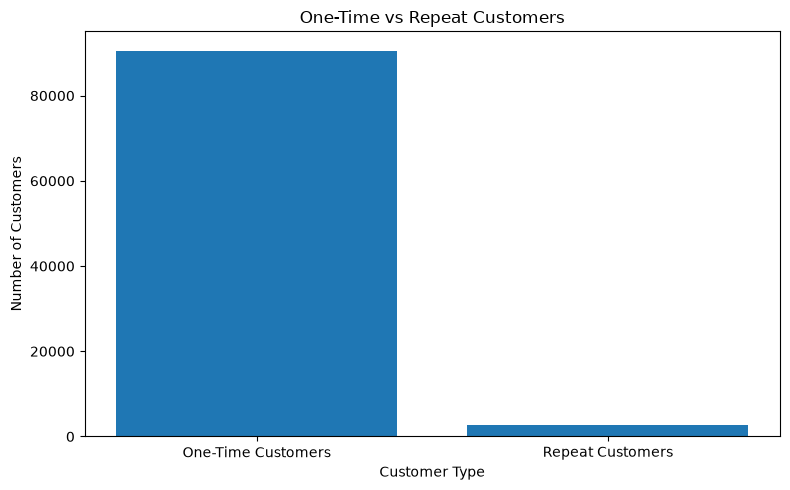

In [10]:

# Customer purchase frequency visualization

customer_types = ["One-Time Customers", "Repeat Customers"]
customer_counts = [one_time_customers, repeat_customers]

plt.figure(figsize=(8, 5))

plt.bar(customer_types, customer_counts)

plt.title("One-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


In [11]:

# Count customers based on number of orders

purchase_frequency = (
    customer_orders["total_orders"]
    .value_counts()
    .sort_index()
)

print("Customer Purchase Frequency:")
display(purchase_frequency)


Customer Purchase Frequency:


total_orders
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

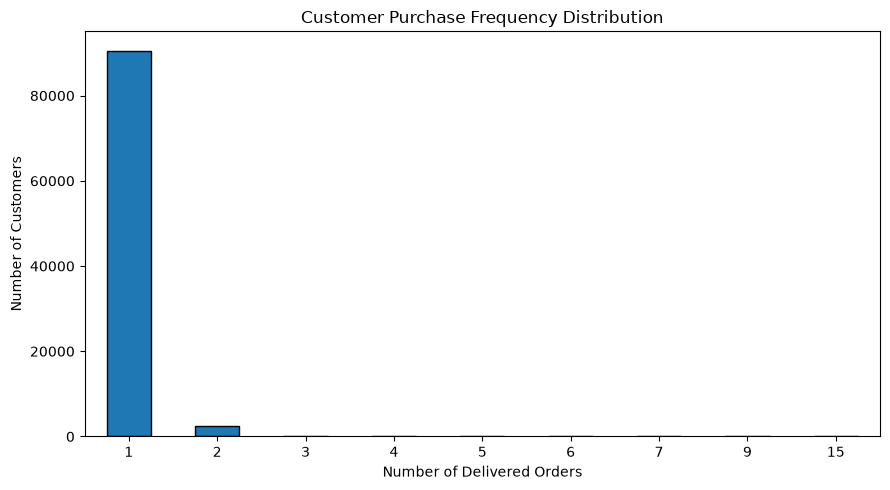

In [12]:

plt.figure(figsize=(9, 5))

purchase_frequency.head(10).plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Customer Purchase Frequency Distribution")
plt.xlabel("Number of Delivered Orders")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()



## 4. Key Findings

- The majority of customers placed only one delivered order.
- A smaller proportion of customers made repeat purchases.
- The repeat customer rate was approximately 3.12%.
- Customer retention is an important opportunity for business growth.

## 5. Business Recommendations

1. Introduce customer loyalty programs.
2. Provide personalized discounts for existing customers.
3. Use email campaigns to encourage repeat purchases.
4. Improve customer experience to increase long-term engagement.

## 6. Conclusion

The customer analysis shows that most customers made only one purchase, while a smaller group returned for additional purchases. Businesses can use these findings to develop customer retention strategies and improve customer lifetime value.
